Machine Learning Assignment 2

Dry Bean Classification Using Multiple Machine Learning Algorithms

In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
import pandas as pd

df = pd.read_excel("Dry_Bean_Dataset.xlsx")

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully
Dataset shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [4]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

In [6]:
df.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [7]:
print(df.columns)

Index(['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
       'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
       'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
       'ShapeFactor3', 'ShapeFactor4', 'Class'],
      dtype='object')


In [8]:
print(df.isnull().sum())

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64


In [9]:
print(df["Class"].value_counts())


Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


In [10]:
X = df.drop("Class", axis=1)
y = df["Class"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nClasses:")
print(y.unique())

X shape: (13611, 16)
y shape: (13611,)

Features:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

Classes:
['SEKER' 'BARBUNYA' 'BOMBAY' 'CALI' 'HOROZ' 'SIRA' 'DERMASON']


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 10888
Testing samples: 2723


In [12]:
from sklearn.model_selection import train_test_split

In [13]:
models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Naive Bayes": GaussianNB(),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            probability=True,
            random_state=42
        ))
    ])
}

In [14]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

print("All libraries imported successfully")

All libraries imported successfully


In [15]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [16]:
%pip install joblib

Note: you may need to restart the kernel to use updated packages.


In [17]:
for name, model in models.items():
    
    print("Training:", name)
    
    model.fit(X_train, y_train)

print("\nAll models trained successfully.")

Training: Logistic Regression
Training: Decision Tree
Training: KNN
Training: Naive Bayes
Training: SVM


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



All models trained successfully.


In [18]:
results = []

classes = np.unique(y_test)

for name, model in models.items():

    print("\nEvaluating:", name)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    mcc = matthews_corrcoef(
        y_test,
        y_pred
    )

    # Probability predictions for multiclass AUC
    y_prob = model.predict_proba(X_test)

    y_test_bin = label_binarize(
        y_test,
        classes=model.classes_
    )

    auc = roc_auc_score(
        y_test_bin,
        y_prob,
        multi_class="ovr",
        average="weighted"
    )

    results.append([
        name,
        accuracy,
        auc,
        precision,
        recall,
        f1,
        mcc
    ])


Evaluating: Logistic Regression

Evaluating: Decision Tree

Evaluating: KNN

Evaluating: Naive Bayes

Evaluating: SVM


In [19]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(10888, 16)
(2723, 16)
(10888,)
(2723,)


In [20]:
models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Naive Bayes": GaussianNB(),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            probability=True,
            random_state=42
        ))
    ])
}

print("5 models created successfully")


5 models created successfully


In [21]:
for name, model in models.items():

    print("Training:", name)

    model.fit(X_train, y_train)

    print(name, "completed")

print("\nAll 5 models trained successfully.")

Training: Logistic Regression
Logistic Regression completed
Training: Decision Tree
Decision Tree completed
Training: KNN
KNN completed
Training: Naive Bayes
Naive Bayes completed
Training: SVM


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM completed

All 5 models trained successfully.


In [22]:
test_predictions = models["Logistic Regression"].predict(X_test)

print("Prediction successful")
print("Number of predictions:", len(test_predictions))
print(test_predictions[:10])

Prediction successful
Number of predictions: 2723
['DERMASON' 'BOMBAY' 'SIRA' 'SEKER' 'BARBUNYA' 'SEKER' 'DERMASON' 'SIRA'
 'CALI' 'HOROZ']


In [23]:
results = []

for name, model in models.items():

    print("Evaluating:", name)

    # Predictions
    y_pred = model.predict(X_test)

    # Class probabilities
    y_prob = model.predict_proba(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    mcc = matthews_corrcoef(
        y_test,
        y_pred
    )

    # Convert actual classes for multiclass AUC
    y_test_bin = label_binarize(
        y_test,
        classes=model.classes_
    )

    auc = roc_auc_score(
        y_test_bin,
        y_prob,
        multi_class="ovr",
        average="weighted"
    )

    results.append([
        name,
        accuracy,
        auc,
        precision,
        recall,
        f1,
        mcc
    ])

print("Evaluation completed successfully")

Evaluating: Logistic Regression
Evaluating: Decision Tree
Evaluating: KNN
Evaluating: Naive Bayes
Evaluating: SVM
Evaluation completed successfully


In [24]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "AUC",
        "Precision",
        "Recall",
        "F1 Score",
        "MCC"
    ]
)

results_df.round(4)

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9214,0.9934,0.9222,0.9214,0.9216,0.9050
1,Decision Tree,0.8917,0.9330,0.8912,0.8917,0.8913,0.8691
2,KNN,0.9166,0.9812,0.9174,0.9166,0.9168,0.8992
3,Naive Bayes,0.7639,0.9644,0.7654,0.7639,0.7615,0.7154
4,SVM,0.9221,0.9937,0.9224,0.9221,0.9222,0.9059


In [25]:
results_df.to_csv("model_results.csv", index=False)

print("Results saved successfully")

Results saved successfully


In [26]:
import os
import joblib

os.makedirs("model", exist_ok=True)

joblib.dump(
    models["Logistic Regression"],
    "model/logistic_regression.joblib"
)

joblib.dump(
    models["Decision Tree"],
    "model/decision_tree.joblib"
)

joblib.dump(
    models["KNN"],
    "model/knn.joblib"
)

joblib.dump(
    models["Naive Bayes"],
    "model/naive_bayes.joblib"
)

joblib.dump(
    models["SVM"],
    "model/svm.joblib"
)

print("All 5 trained models saved successfully.")

All 5 trained models saved successfully.


In [27]:
test_data = X_test.copy()

test_data["Class"] = y_test.values

test_data.to_csv(
    "test_data.csv",
    index=False
)

print("test_data.csv created successfully")
print("Shape:", test_data.shape)

test_data.head()

test_data.csv created successfully
Shape: (2723, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
12803,36002,700.889,257.888986,178.268649,1.446631,0.722605,36368,214.100841,0.797386,0.989936,0.920954,0.830205,0.007163,0.002099,0.689241,0.997078,DERMASON
3713,183825,1594.423,582.225240,402.762055,1.445581,0.722124,185116,483.790512,0.797852,0.993026,0.908672,0.830934,0.003167,0.000931,0.690451,0.998102,BOMBAY
8974,45595,801.717,301.092828,193.505323,1.555992,0.766138,46054,240.942643,0.769926,0.990033,0.891425,0.800227,0.006604,0.001670,0.640363,0.996401,SIRA
1743,45084,763.811,261.138204,219.977872,1.187111,0.538882,45425,239.588672,0.773098,0.992493,0.971092,0.917478,0.005792,0.002532,0.841767,0.999271,SEKER
2303,61645,952.199,335.139136,235.843970,1.421021,0.710478,62499,280.158619,0.795522,0.986336,0.854382,0.835947,0.005437,0.001638,0.698808,0.993020,BARBUNYA


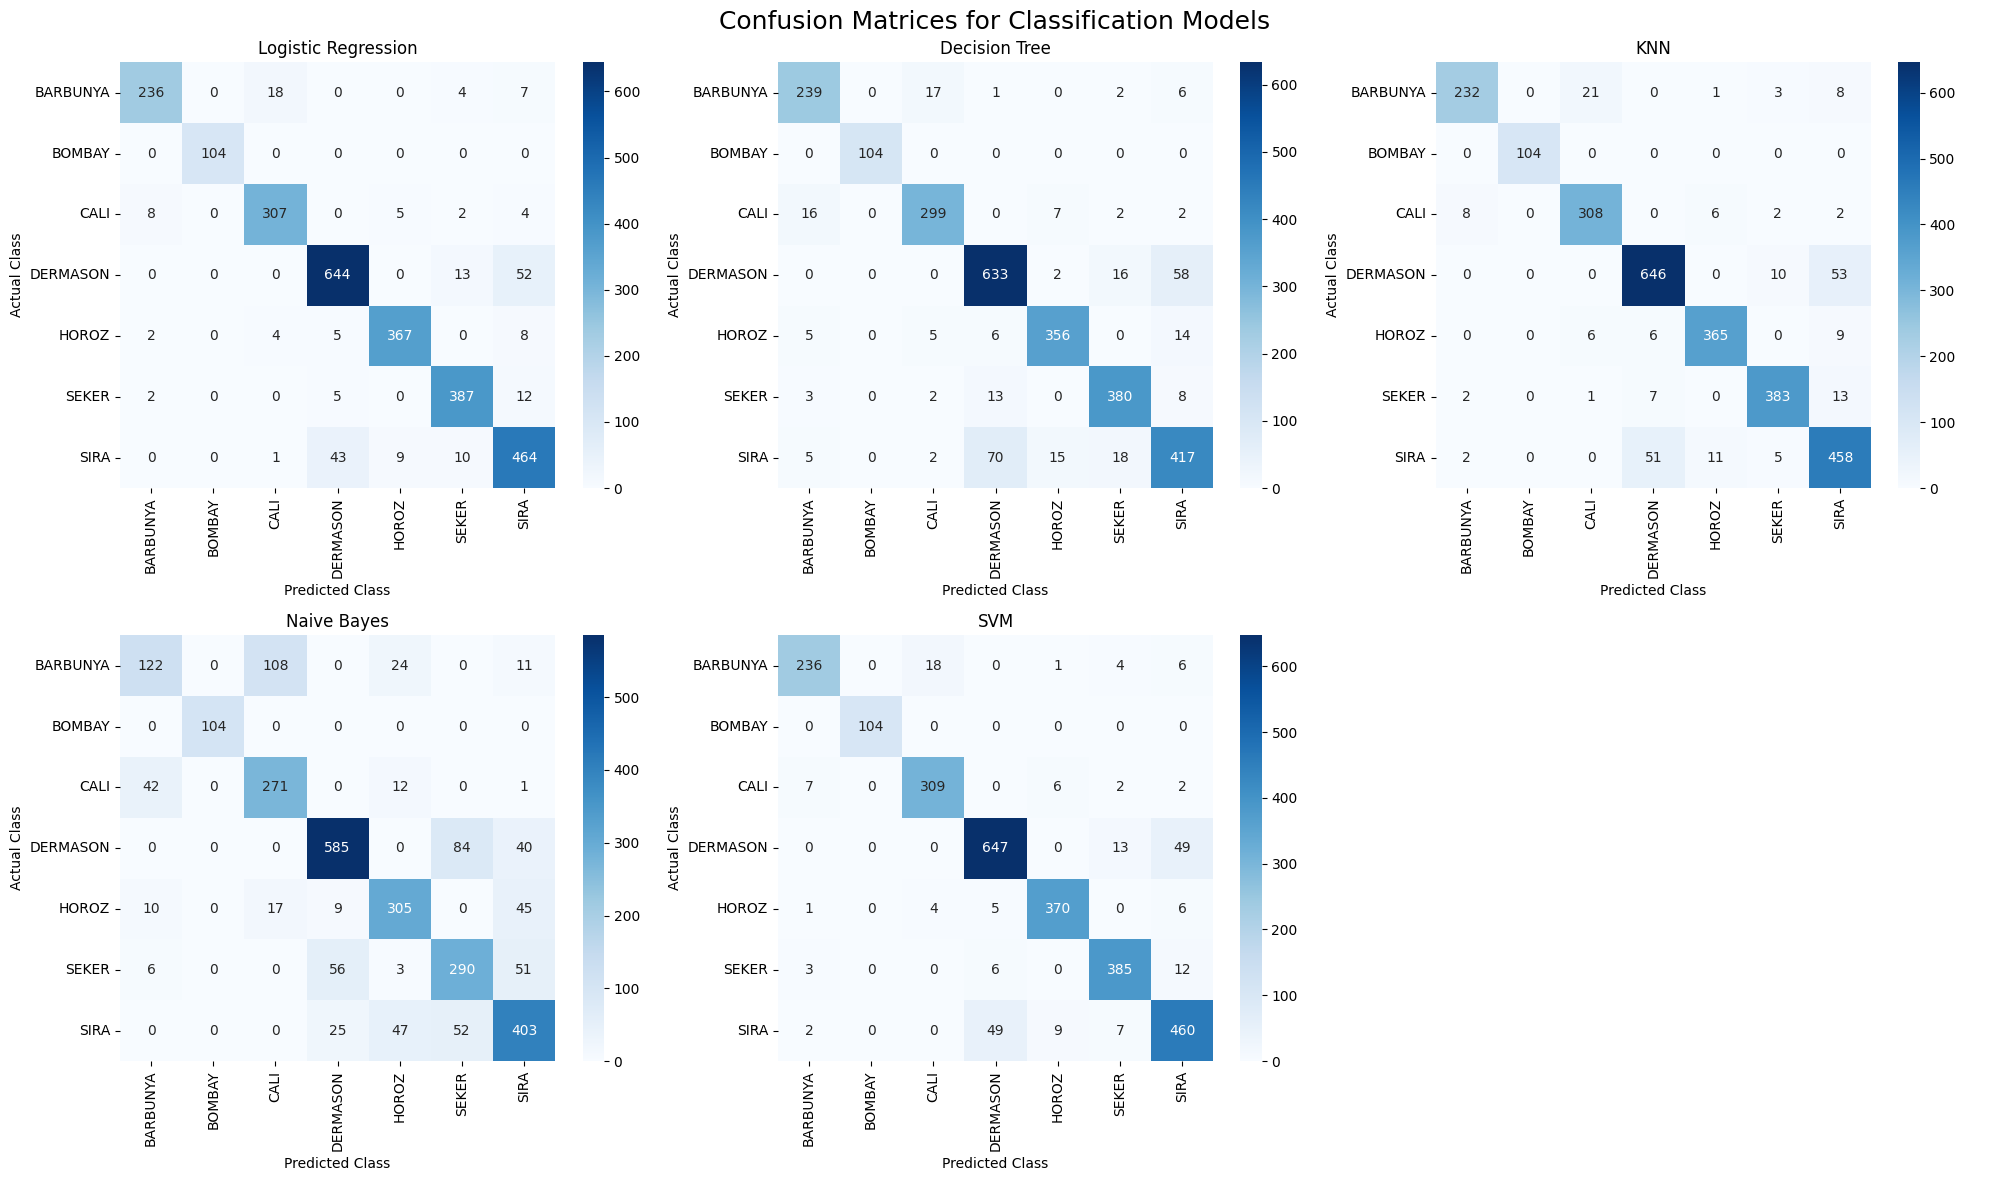

In [28]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(20, 12)
)

axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=model.classes_
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[i],
        xticklabels=model.classes_,
        yticklabels=model.classes_
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Class")
    axes[i].set_ylabel("Actual Class")

axes[-1].axis("off")

plt.suptitle(
    "Confusion Matrices for Classification Models",
    fontsize=18
)

plt.tight_layout()
plt.show()

In [29]:
best_model = models["SVM"]

y_pred_svm = best_model.predict(X_test)

print("SVM Classification Report")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_svm
    )
)

SVM Classification Report
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.95      0.94       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.96      0.96       386
       SEKER       0.94      0.95      0.94       406
        SIRA       0.86      0.87      0.87       527

    accuracy                           0.92      2723
   macro avg       0.94      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



Logistic Regression

Logistic Regression achieved 92.14% accuracy with an AUC of 0.9934 and MCC of 0.9050. This indicates strong multiclass classification performance and suggests that the standardized features provide substantial separation among the bean classes.

Decision Tree

Decision Tree achieved 89.17% accuracy, which is lower than Logistic Regression, KNN and SVM. Its MCC of 0.8691 nevertheless indicates strong agreement between predictions and actual classes.

KNN

KNN achieved 91.66% accuracy and an F1 score of 0.9168. Its performance is close to Logistic Regression and SVM, indicating that the standardized feature space provides useful neighborhood information for classifying bean varieties.

Naive Bayes

Naive Bayes produced the lowest overall performance, with 76.39% accuracy, an F1 score of 0.7615, and MCC of 0.7154. Although its AUC remained relatively high at 0.9644, the considerably lower accuracy and F1 score show that it was less effective for final class assignment than the other classifiers.

SVM

SVM achieved the strongest overall results, with 92.21% accuracy, 0.9937 AUC, 92.24% precision, 92.21% recall, 92.22% F1, and 0.9059 MCC.

Therefore:

SVM is the best-performing model in this experiment\boxed{\text{SVM is the best-performing model in this experiment}}SVM is the best-performing model in this experiment​

The difference versus Logistic Regression is very small, however:

92.21%−92.14%=0.07%92.21\%-92.14\%=0.07\%92.21%−92.14%=0.07%

So a good analysis should mention that SVM ranks first, but Logistic Regression performs almost identically.

In [31]:
best_model = results_df.loc[
    results_df["F1 Score"].idxmax()
]

print("Best model based on F1 Score:")
print(best_model)

Best model based on F1 Score:
Model             SVM
Accuracy     0.922145
AUC           0.99368
Precision    0.922426
Recall       0.922145
F1 Score     0.922177
MCC           0.90587
Name: 4, dtype: object


In [32]:
print("Saved models:")
print(os.listdir("model"))

print("\ntest_data.csv:", os.path.exists("test_data.csv"))
print("confusion_matrices.png:", os.path.exists("confusion_matrices.png"))

Saved models:
['decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'naive_bayes.joblib', 'svm.joblib']

test_data.csv: True
confusion_matrices.png: True


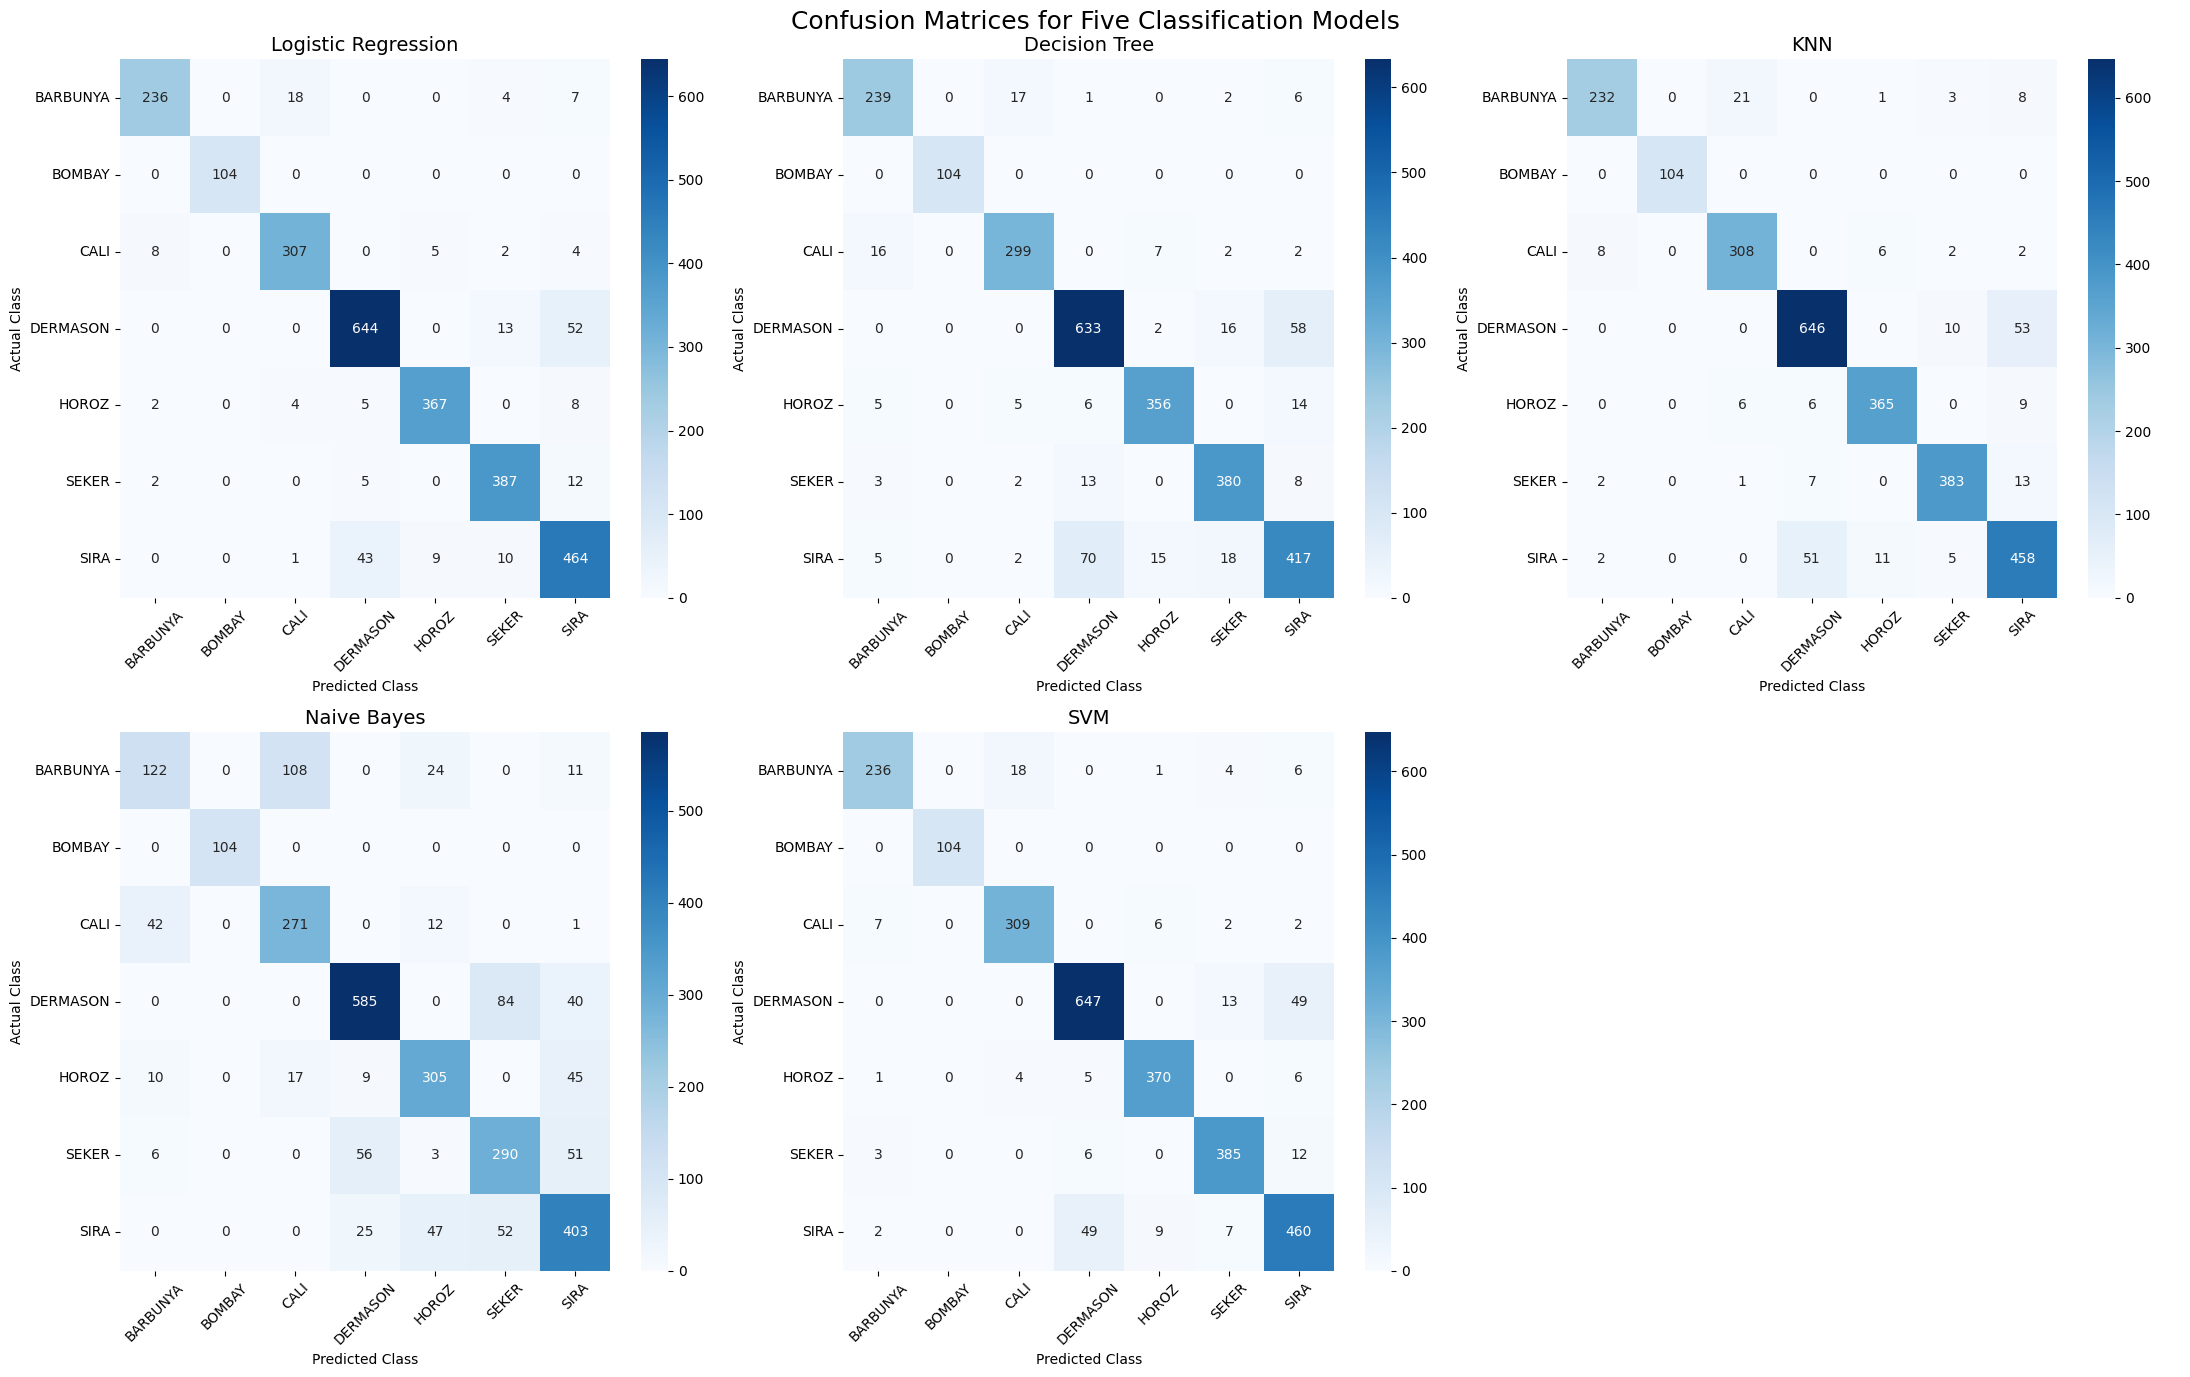

Confusion matrices generated successfully.
Image saved as: confusion_matrices.png


In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Create space for 5 confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(22, 14))

axes = axes.flatten()

# Generate confusion matrix for each trained model
for i, (name, model) in enumerate(models.items()):

    # Make predictions using the already trained model
    y_pred = model.predict(X_test)

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=model.classes_
    )

    # Draw confusion matrix
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[i],
        xticklabels=model.classes_,
        yticklabels=model.classes_
    )

    axes[i].set_title(name, fontsize=14)
    axes[i].set_xlabel("Predicted Class")
    axes[i].set_ylabel("Actual Class")

    axes[i].tick_params(axis="x", rotation=45)
    axes[i].tick_params(axis="y", rotation=0)

# Hide unused sixth position
axes[5].axis("off")

plt.suptitle(
    "Confusion Matrices for Five Classification Models",
    fontsize=18
)

plt.tight_layout()

# Save image BEFORE displaying it
plt.savefig(
    "confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrices generated successfully.")
print("Image saved as: confusion_matrices.png")

In [34]:
import os

print("=== FINAL FILE CHECK ===")

print("\n1. Model folder:")
print(os.listdir("model"))

print("\n2. Test data:")
print("test_data.csv =", os.path.exists("test_data.csv"))

print("\n3. Confusion Matrix:")
print(
    "confusion_matrices.png =",
    os.path.exists("confusion_matrices.png")
)

print("\n4. Model Results:")
print(
    "model_results.csv =",
    os.path.exists("model_results.csv")
)

=== FINAL FILE CHECK ===

1. Model folder:
['decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'naive_bayes.joblib', 'svm.joblib']

2. Test data:
test_data.csv = True

3. Confusion Matrix:
confusion_matrices.png = True

4. Model Results:
model_results.csv = True


In [35]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

from sklearn.preprocessing import label_binarize


st.set_page_config(
    page_title="Dry Bean Classification",
    layout="wide"
)

st.title("Dry Bean Classification")
st.write("Machine Learning Assignment 2")

st.write(
    "Upload the test dataset and select a trained classification "
    "model to evaluate its performance."
)


# -----------------------------
# Model selection
# -----------------------------

model_files = {
    "Logistic Regression": "model/logistic_regression.joblib",
    "Decision Tree": "model/decision_tree.joblib",
    "KNN": "model/knn.joblib",
    "Naive Bayes": "model/naive_bayes.joblib",
    "SVM": "model/svm.joblib"
}

selected_model = st.selectbox(
    "Select Classification Model",
    list(model_files.keys())
)


# -----------------------------
# Upload CSV
# -----------------------------

uploaded_file = st.file_uploader(
    "Upload test_data.csv",
    type=["csv"]
)


if uploaded_file is not None:

    df = pd.read_csv(uploaded_file)

    st.subheader("Uploaded Dataset")
    st.dataframe(df.head())

    # Check target column
    if "Class" not in df.columns:

        st.error(
            "The uploaded CSV must contain a 'Class' column."
        )

    else:

        X_test = df.drop("Class", axis=1)
        y_test = df["Class"]

        # Load previously trained model
        model = joblib.load(
            model_files[selected_model]
        )

        # Generate predictions
        y_pred = model.predict(X_test)

        # Generate class probabilities
        y_prob = model.predict_proba(X_test)

        # -----------------------------
        # Evaluation metrics
        # -----------------------------

        accuracy = accuracy_score(
            y_test,
            y_pred
        )

        precision = precision_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        )

        recall = recall_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        )

        f1 = f1_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        )

        mcc = matthews_corrcoef(
            y_test,
            y_pred
        )

        y_test_bin = label_binarize(
            y_test,
            classes=model.classes_
        )

        auc = roc_auc_score(
            y_test_bin,
            y_prob,
            multi_class="ovr",
            average="weighted"
        )


        # -----------------------------
        # Display metrics
        # -----------------------------

        st.subheader(
            f"{selected_model} Performance"
        )

        col1, col2, col3 = st.columns(3)

        col1.metric(
            "Accuracy",
            f"{accuracy:.4f}"
        )

        col2.metric(
            "AUC",
            f"{auc:.4f}"
        )

        col3.metric(
            "Precision",
            f"{precision:.4f}"
        )

        col4, col5, col6 = st.columns(3)

        col4.metric(
            "Recall",
            f"{recall:.4f}"
        )

        col5.metric(
            "F1 Score",
            f"{f1:.4f}"
        )

        col6.metric(
            "MCC",
            f"{mcc:.4f}"
        )


        # -----------------------------
        # Confusion Matrix
        # -----------------------------

        st.subheader("Confusion Matrix")

        cm = confusion_matrix(
            y_test,
            y_pred,
            labels=model.classes_
        )

        fig, ax = plt.subplots(
            figsize=(10, 7)
        )

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=model.classes_,
            yticklabels=model.classes_,
            ax=ax
        )

        ax.set_xlabel("Predicted Class")
        ax.set_ylabel("Actual Class")
        ax.set_title(
            f"{selected_model} Confusion Matrix"
        )

        plt.xticks(rotation=45)
        plt.yticks(rotation=0)

        st.pyplot(fig)


        # -----------------------------
        # Classification Report
        # -----------------------------

        st.subheader("Classification Report")

        report = classification_report(
            y_test,
            y_pred,
            output_dict=True,
            zero_division=0
        )

        report_df = pd.DataFrame(
            report
        ).transpose()

        st.dataframe(
            report_df.round(4)
        )


else:

    st.info(
        "Please upload test_data.csv to evaluate a model."
    )

Overwriting app.py


In [36]:
import os

print("app.py exists:", os.path.exists("app.py"))

app.py exists: True


In [37]:
print(os.listdir())

['.ipynb_checkpoints', 'AkashShukla.ipynb', 'Dry_Bean_Dataset.xlsx', 'ML_Assignment_2_Akash_Shukla.ipynb', 'model', 'model_results.csv', 'Quetion1_Akash_Shukla.ipynb', 'test_data.csv', 'Untitled.ipynb', 'Untitled1.ipynb', 'confusion_matrices.png', 'app.py']


In [38]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [39]:
!streamlit run app.py

2026-11-08 15:05:24.820 Uvicorn server started on :::8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://10.3.25.231:8502

  Help agents write better Streamlit apps?
  Install the official Streamlit skills by running streamlit skills in your terminal.

^C
  Stopping...


In [79]:
%%writefile requirements.txt
streamlit
pandas
numpy
scikit-learn
matplotlib
seaborn
joblib
openpyxl

Overwriting requirements.txt


In [80]:
import os
print(os.path.exists("requirements.txt"))

True


In [86]:
%%writefile README.md
# Dry Bean Classification Using Machine Learning

## Machine Learning Assignment 2

**Student Name:** Akash Shukla  
**Course:** M.Tech Artificial Intelligence and Machine Learning  
**Institution:** BITS Pilani WILP  

---

## 1. Problem Statement

The objective of this project is to develop and compare multiple machine learning classification models for identifying dry bean varieties using geometric and shape-related features extracted from bean images.

Five classification algorithms were trained and evaluated using the same training and testing datasets:

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Support Vector Machine

A Streamlit web application was developed to evaluate the saved models using an uploaded test CSV file. The application loads the previously trained model and does not retrain it during evaluation.

---

## 2. Dataset Description

The Dry Bean Dataset from the UCI Machine Learning Repository was used for this project.

The dataset contains:

- 13,611 observations
- 16 numerical input features
- 7 dry bean classes
- No missing values
- One target column named `Class`

The seven bean classes are:

- BARBUNYA
- BOMBAY
- CALI
- DERMASON
- HOROZ
- SEKER
- SIRA

The input features represent geometric and shape-related characteristics such as area, perimeter, major axis length, minor axis length, aspect ratio, eccentricity, convex area, equivalent diameter, extent, solidity, roundness, compactness, and shape factors.

Dataset source:

https://archive.ics.uci.edu/dataset/602/dry+bean+dataset

---

## 3. Data Preprocessing

The following preprocessing steps were performed:

1. The dataset was loaded using pandas.
2. Dataset dimensions, data types, descriptive statistics, class distribution, and missing values were examined.
3. The `Class` column was used as the target variable.
4. The remaining 16 columns were used as input features.
5. The dataset was divided into 80% training data and 20% testing data.
6. Stratified sampling was used to maintain class proportions.
7. `random_state=42` was used for reproducibility.
8. StandardScaler was applied to Logistic Regression, KNN, and SVM using scikit-learn pipelines.
9. The preprocessing step and classifier were saved together inside each applicable pipeline.

The split produced:

- Training records: 10,888
- Testing records: 2,723

---

## 4. Machine Learning Models

### 4.1 Logistic Regression

Logistic Regression was implemented using standardized numerical features. The maximum number of iterations was increased to support convergence for the multiclass dataset.

### 4.2 Decision Tree

The Decision Tree classifier was trained without feature scaling because tree-based methods are generally not sensitive to differences in feature magnitude.

### 4.3 K-Nearest Neighbors

KNN was implemented with five neighbors. StandardScaler was used because distance-based algorithms are affected by feature magnitude.

### 4.4 Gaussian Naive Bayes

Gaussian Naive Bayes was implemented using the original numerical feature values. The model assumes conditional independence among features for each class.

### 4.5 Support Vector Machine

SVM was implemented with probability estimation enabled. StandardScaler was used before model training. Probability estimates were used to calculate multiclass AUC.

---

## 5. Evaluation Metrics

All models were evaluated using the following metrics:

- Accuracy
- Area Under the ROC Curve
- Weighted Precision
- Weighted Recall
- Weighted F1 Score
- Matthews Correlation Coefficient

For multiclass AUC, the One-vs-Rest method with weighted averaging was used.

---

## 6. Model Performance Results

| Model | Accuracy | AUC | Precision | Recall | F1 Score | MCC |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.9214 | 0.9934 | 0.9222 | 0.9214 | 0.9216 | 0.9050 |
| Decision Tree | 0.8917 | 0.9330 | 0.8912 | 0.8917 | 0.8913 | 0.8691 |
| K-Nearest Neighbors | 0.9166 | 0.9812 | 0.9174 | 0.9166 | 0.9168 | 0.8992 |
| Gaussian Naive Bayes | 0.7639 | 0.9644 | 0.7654 | 0.7639 | 0.7615 | 0.7154 |
| Support Vector Machine | **0.9221** | **0.9937** | **0.9224** | **0.9221** | **0.9222** | **0.9059** |

---

## 7. Model Observations

### Logistic Regression

Logistic Regression achieved 92.14% accuracy, an AUC of 0.9934, and an MCC of 0.9050. The model provided strong multiclass classification performance and performed almost as well as SVM.

### Decision Tree

Decision Tree achieved 89.17% accuracy and an MCC of 0.8691. Its performance was lower than Logistic Regression, KNN, and SVM. The result indicates that a single tree may not generalize as effectively as the stronger models used in this experiment.

### K-Nearest Neighbors

KNN achieved 91.66% accuracy, an AUC of 0.9812, and an F1 score of 0.9168. The result indicates that similar bean samples form useful neighborhoods in the standardized feature space.

### Gaussian Naive Bayes

Gaussian Naive Bayes achieved 76.39% accuracy, an F1 score of 0.7615, and an MCC of 0.7154. It produced the lowest overall performance among the five models.

Several geometric measurements in the dataset are related to one another. Therefore, the conditional-independence assumption of Naive Bayes may not represent the feature relationships as effectively as the other models.

### Support Vector Machine

SVM achieved the best overall results:

- Accuracy: 92.21%
- AUC: 0.9937
- Precision: 92.24%
- Recall: 92.21%
- F1 Score: 92.22%
- MCC: 0.9059

The confusion matrix and classification report also demonstrated strong classification performance across the seven dry bean varieties.

### Best Model

Support Vector Machine was identified as the best-performing model because it achieved the highest value for all six evaluation measures.

The performance difference between SVM and Logistic Regression was small. SVM accuracy was only 0.07 percentage points higher than Logistic Regression accuracy. Therefore, Logistic Regression may still be considered when model simplicity and interpretability are important.

---

## 8. Streamlit Application

The Streamlit application allows the user to:

1. Upload a CSV test dataset.
2. Select one of the five trained classifiers.
3. Load the selected saved model.
4. Generate predictions without retraining the classifier.
5. Display Accuracy, AUC, Precision, Recall, F1 Score, and MCC.
6. Display the confusion matrix.
7. Display the detailed classification report.

The uploaded CSV file must contain:

- The same 16 input features used during training
- A target column named `Class`

---

## 9. Repository Structure

Overwriting README.md


In [88]:
pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.
